In [167]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
import plot_toe_eddies as plot
import class_EDDIES as ed
import pandas as pd
from pathlib import Path

In [168]:
def plot_mcells_modif(ax,cartmap,mat_eddies,type):
    """load eddy detection information from daily adt_yyyymmdd.mat
    and plot the eddy positions & contours
    """
    proj,crs,extent = cartmap
    xv,yv = f.box_square(extent[2],extent[-1],extent[0],extent[1])
    if type==-1:
        VAR,Name  = 'Cyclonic_Cell','Ncyclo'
        col  = 'b'
    elif type==1:
        VAR,Name  = 'Anticyclonic_Cell','Nanti'
        col='r'
    TCell = mat_eddies[VAR]
    Neddies=int(mat_eddies[Name][:][0][0])
    for n in range(0,Neddies):
        xcen = f.mod_shift(mat_eddies[TCell[2][n]][:])
        ycen = mat_eddies[TCell[3][n]][:]
        control = f.inpolygon(xcen,ycen, xv, yv)
        if control == True:
            xout = f.mod_shift(mat_eddies[TCell[4][n]][:])
            yout = mat_eddies[TCell[5][n]][:]
            xmax = f.mod_shift(mat_eddies[TCell[8][n]][:])
            ymax = mat_eddies[TCell[9][n]][:]
            ax.scatter(xcen,ycen,10,c='k',zorder=15,transform=crs)
            ax.plot(xmax,ymax,'-',transform=crs,color=col,linewidth=2,zorder=15)
            #ax.plot(xout,yout,'k--',transform=crs,linewidth=1,zorder=15)
       

In [169]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

In [170]:
date = '2026-06-30'
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
ship_center = (dm_to_dd(11, 38.168), dm_to_dd(37, 24.128, True))
sab_1 = (11.9586, -38.1608)
sab_2 = (12.3168, -38.6997)
s1_x, s1_y = sab_1
s2_x, s2_y = sab_2
ship_x, ship_y = ship_center

In [172]:
##### POSITION VARIABLES #####
ft=10
lon_min, lon_max, lat_min, lat_max = 7, 20, -42, -33
pos_west,pos_east,pos_south,pos_north  = 7, 20, -42,-33  #Reset the area
proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [173]:
dir = f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date}/"
dir_eddies = dir + f"2026-07-01_toeddies/"
fname_bathy = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/bathymetry/etopo2.nc"
ctd_path = "/Volumes/science/MD252_WHIRLS/CTD/data/"
save_fig = f"/Volumes/science/MD252_WHIRLS/REP/daily_figures/{date}/"
adt_path= f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date}/{date}_cmems_data_grib/adt.grb2"
adcp_path = "/Volumes/science/MD252_WHIRLS/ADCP_FROM_XAVIER/WHIRLS_BB38_TOT_osite.nc"
sst_path = f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date}/sst/analysed_sst.grb2"

In [174]:
date="2026-07-01"

In [175]:
lst_adt_data = cfgrib.open_datasets(adt_path)
adt_data = lst_adt_data[0]

In [176]:
lats = adt_data['latitude']
lons = adt_data['longitude']
time = adt_data['time']
adt = adt_data['zos']

In [177]:
lst_sst_data = cfgrib.open_datasets(sst_path)
sst_data = lst_sst_data[0]

Ignoring index file '/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/2026-06-30/sst/analysed_sst.grb2.5b7b6.idx' incompatible with GRIB file
Ignoring index file '/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/2026-06-30/sst/analysed_sst.grb2.5b7b6.idx' incompatible with GRIB file


In [178]:
path_nav = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/NAV/"
files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [180]:
lats_sst = sst_data['latitude']
lons_sst = sst_data['longitude']
time = sst_data['time']
sst = sst_data['unknown']-273.15

In [181]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [183]:
depth_subset = np.where(depth_subset > 0, 0, depth_subset)

In [184]:
files = os.listdir("/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/2026-07-01/2026-07-01_toeddies")


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


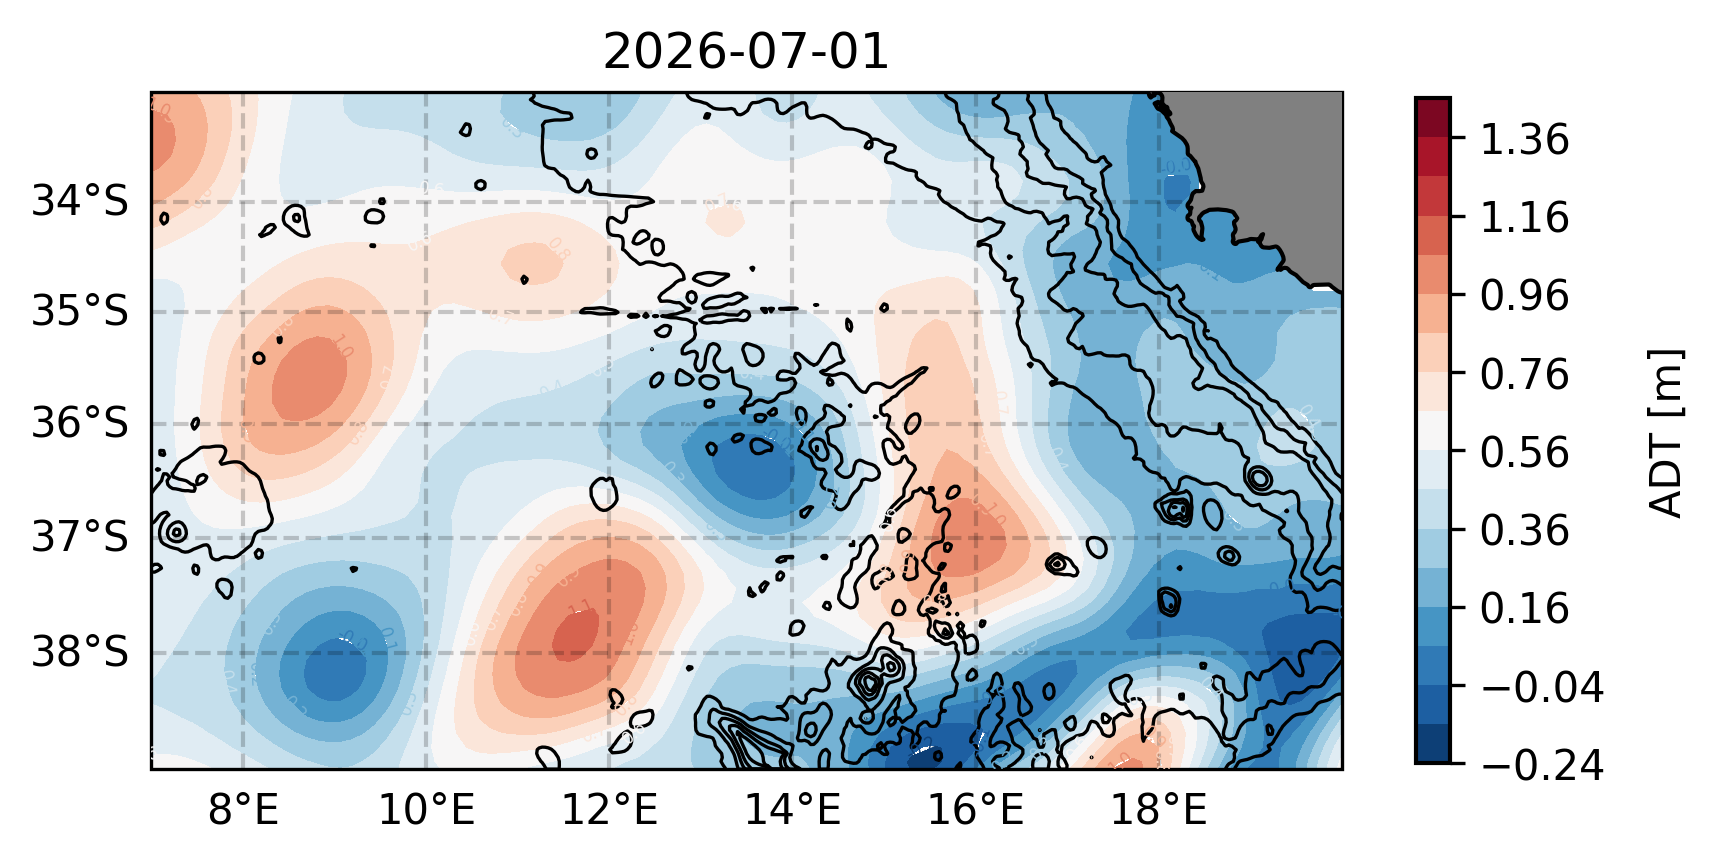

In [185]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="black", linestyles='solid', transform=crs, linewidths=0.8)


# ADT contours
c2 = ax0.contourf(lons, lats, adt,  np.arange(-0.24, 1.5, 0.1), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7)

ax0.clabel(c2, inline=True, fontsize=4, fmt='%1.1f')
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)


In [186]:
dir_eddies = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/2026-07-01/2026-07-01_toeddies/"

In [187]:
files = os.listdir("/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/2026-07-01/2026-07-01_toeddies/")
for fname in files:
    if "anti" in fname:
        if "maxspeed" in fname:
            gdf_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdf_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdf_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")
    else:
        if "maxspeed" in fname:
            gdfcyc_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdfcyc_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdfcyc_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")


In [189]:
adcp = nc.Dataset(adcp_path)
adcp_lons = adcp['LONGITUDE']
adcp_lats = adcp['LATITUDE']

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


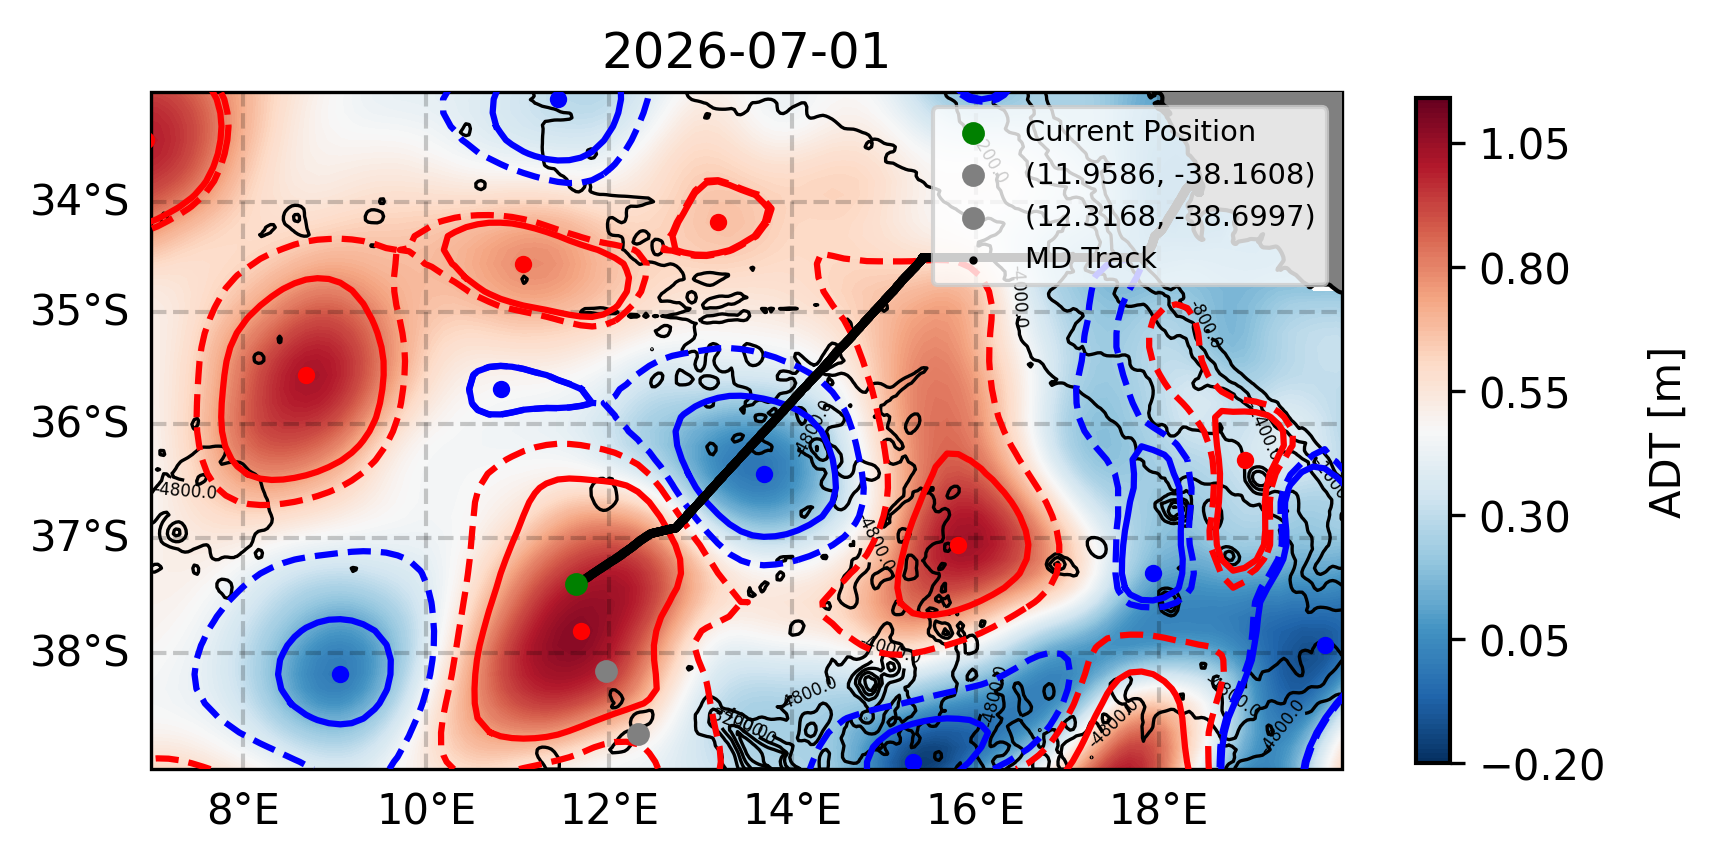

In [192]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="black", linestyles='solid', transform=crs, linewidths=0.8)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(-0.2, 1.15, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="Current Position")
ax0.scatter(s1_x, s1_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s1_x, s1_y}")
ax0.scatter(s2_x, s2_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s2_x, s2_y}")
# ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, label="MD Track", color='black', zorder=90)
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


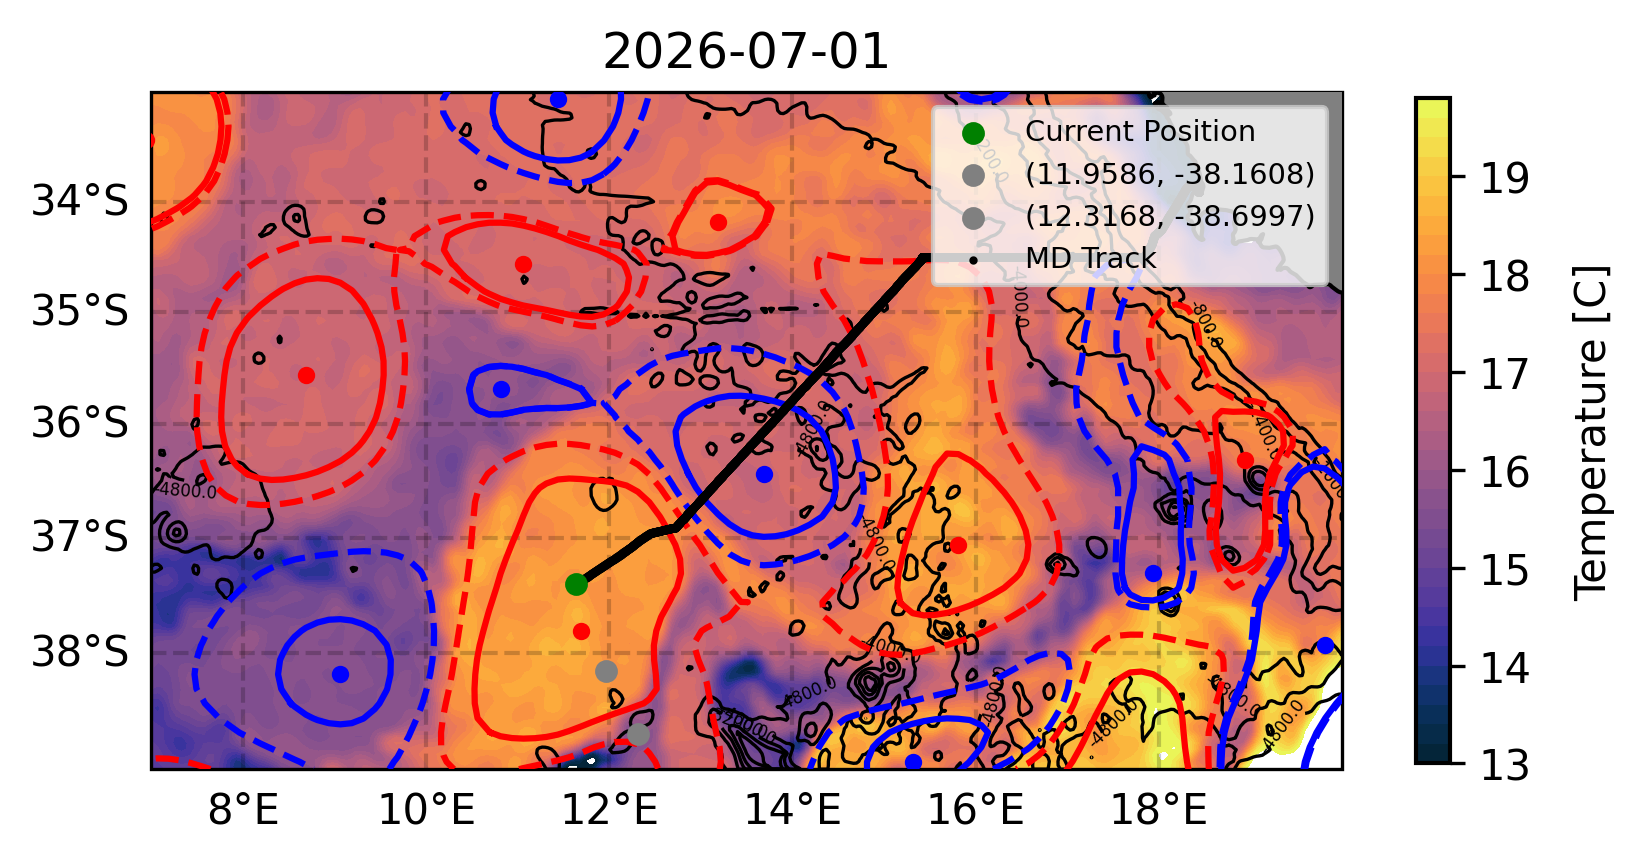

In [193]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="black", linestyles='solid', transform=crs, linewidths=0.8)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons_sst, lats_sst, sst, levels=np.arange(13, 20, 0.2), cmap=cmocean.cm.thermal,
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(13, 20, 1))
cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="Current Position")
ax0.scatter(s1_x, s1_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s1_x, s1_y}")
ax0.scatter(s2_x, s2_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s2_x, s2_y}")
# ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, label="MD Track", color='black', zorder=90)
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 

In [40]:
path_nav = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/NAV/"
files = os.listdir(path_nav)
lats = []
longs = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lats.append(ds['lat'])
    longs.append(ds['long'])

    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [38]:
ds

<xarray.Dataset> Size: 8MB
Dimensions:      (time: 86369)
Coordinates:
  * time         (time) datetime64[ns] 691kB 2026-06-29T00:00:01.194912256 .....
Data variables: (12/16)
    gndcourse    (time) float32 345kB ...
    driftspeed   (time) float32 345kB ...
    heading      (time) float32 345kB ...
    alt          (time) float64 691kB ...
    roll         (time) float32 345kB ...
    driftcourse  (time) float32 345kB ...
    ...           ...
    surfcourse   (time) float32 345kB ...
    pitch        (time) float32 345kB ...
    heave        (time) float32 345kB ...
    gpstime      (time) datetime64[ns] 691kB ...
    lat          (time) float64 691kB ...
    gndspeed     (time) float32 345kB ...
Attributes: (12/24)
    history:                       TECHSAS V5.11 2026-06-29T00:00:01Z
    source:                        Acquisition of shipnav techsas
    conventions:                   CF-1.0.
    creationtime:                  2026-06-29T00:00:01Z
    device_firstusedate:           2000-01-01T00:00:00Z
    device_deviceid:               MD_SHIPNAV
    ...                            ...
    frame_minor:                   0
    frame_sourcetype:              nav
    frame_period:                  1.0
    title:                         Technical and Scientific sensors Acquisiti...
    institution:                   IFR
    reference:                     http://www.ifremer.fr

In [36]:
file = files[0]

with open(path_nav + file, "rb") as f:
    print(f.read(4))

b'CDF\x01'
